In [1]:
%pip -q install tokenizers gensim scikit-learn matplotlib pandas numpy

In [2]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [3]:
KORPUS_BUDOWLA = ['Na wzgórzu stoi stary zamek otoczony wysokim murem.', 'Turysta ogląda zamek i fotografuje kamienną wieżę.', 'W średniowieczu zamek chronił mieszkańców przed najazdem.', 'Rycerz wracał do domu, a zamek był już zamknięty.', 'Przewodnik opowiadał, jak zamek bronił całej okolicy.', 'Historyk bada zamek oraz dawne życie rycerzy.', 'Na mapie zamek leży obok rzeki i lasu.', 'Kamienny zamek posiada szeroką bramę i dziedziniec.', 'Z wieży widać zamek oraz pobliskie pola.', 'Król zbudował zamek na wysokim skalistym wzgórzu.', 'Podczas wycieczki dzieci zwiedzały zamek i muzeum.', 'Wiosną zamek przyciąga turystów z całej Polski.', 'Odrestaurowany zamek ma piękny ogród i wieżę.', 'Archeolog odkrył, że zamek powstał wiele wieków temu.', 'Wieczorem oświetlony zamek wyglądał bardzo tajemniczo.', 'Książę zaprosił gości, a zamek przygotowano na ucztę.', 'Przy bramie rycerz pilnował wejścia, a zamek pozostawał bezpieczny.', 'Stary zamek ma grube mury i szeroki dziedziniec.', 'Zabytkowy zamek można odwiedzić podczas wakacji.', 'W muzeum pokazano, jak zamek wyglądał w dawnych czasach.']
KORPUS_MECHANIZM = ['Ślusarz wymienił zamek w drzwiach mieszkania.', 'Nowy zamek zabezpiecza drzwi przed otwarciem.', 'Mechanik sprawdził zamek i dopasował metalowy klucz.', 'Zacięty zamek utrudniał wejście do garażu.', 'Klucz obracał się ciężko, ponieważ zamek był uszkodzony.', 'W sklepie kupiłem zamek do drzwi wejściowych.', 'Stary zamek miał pękniętą sprężynę w mechanizmie.', 'Po naprawie zamek działał płynnie i cicho.', 'Monter zamocował zamek w metalowej furtce.', 'Elektroniczny zamek otwiera drzwi po wpisaniu kodu.', 'Zapasowy klucz pasuje do zamka, ale zamek czasem się zacina.', 'Pracownik nasmarował zamek, żeby łatwiej przekręcać klucz.', 'Bezpieczny zamek ma solidny mechanizm i stalową obudowę.', 'Kiedy klucz zginął, zamek trzeba było wymienić.', 'Nowoczesny zamek działa za pomocą specjalnej karty.', 'Ślusarz pokazał, jak zamek blokuje zasuwę drzwi.', 'Zepsuty zamek nie pozwalał zamknąć furtki.', 'Właściciel wybrał zamek odporny na próby włamania.', 'Wewnętrzny zamek zawiera małe metalowe elementy.', 'Zamontowany zamek sprawdzono kilka razy kluczem.']
KORPUS_TLO = ['Przy dużej rzece znajduje się spokojna wieś.', 'W lesie rosną wysokie drzewa i kolorowe kwiaty.', 'Każdego ranka słońce oświetla pobliskie jezioro.', 'Na stole leży książka oraz filiżanka herbaty.', 'Komputer uruchamia program do analizy danych.', 'Student czyta artykuł o sztucznej inteligencji.', 'W ogrodzie rosną pomidory i zielona sałata.', 'Pociąg odjeżdża z dworca późnym popołudniem.', 'Kierowca zatrzymał samochód przed czerwonym światłem.', 'Pies odpoczywa na dywanie obok kanapy.', 'Kolega przygotował obiad dla całej rodziny.', 'W bibliotece można wypożyczyć ciekawą powieść.', 'Zimą temperatura spada poniżej zera.', 'Na boisku dzieci grały w piłkę nożną.', 'W kuchni pachnie świeżo upieczonym chlebem.', 'Lekarz zapisał wynik badania w komputerze.', 'Na parkingu stoi czerwony motocykl.', 'Rowerzysta jedzie spokojnie po ścieżce.', 'W parku spacerują ludzie z psami.', 'Wieczorem obejrzeliśmy ciekawy film przyrodniczy.']
KORPUS = KORPUS_BUDOWLA + KORPUS_MECHANIZM + KORPUS_TLO

def przygotuj(s):
    return re.findall(r"[^\W_]+", s.lower(), flags=re.UNICODE)

ZDANIA = [przygotuj(s) for s in KORPUS]
assert len(KORPUS_BUDOWLA) == len(KORPUS_MECHANIZM) == len(KORPUS_TLO) == 20
assert len(set(KORPUS)) == 60
assert all(przygotuj(s).count("zamek") == 1 for s in KORPUS_BUDOWLA + KORPUS_MECHANIZM)
assert all("zamek" not in przygotuj(s) for s in KORPUS_TLO)
print("Źródło: zdania przygotowane na potrzeby ćwiczenia")
print("Budowla:", len(KORPUS_BUDOWLA), "Mechanizm:", len(KORPUS_MECHANIZM), "Tło:", len(KORPUS_TLO), "Razem:", len(KORPUS))
print("Przygotowanie: małe litery, usunięcie interpunkcji, podział na słowa")
print("Przykłady:")
for s in [KORPUS_BUDOWLA[0], KORPUS_MECHANIZM[0], KORPUS_TLO[0]]:
    print(s)

Źródło: zdania przygotowane na potrzeby ćwiczenia
Budowla: 20 Mechanizm: 20 Tło: 20 Razem: 60
Przygotowanie: małe litery, usunięcie interpunkcji, podział na słowa
Przykłady:
Na wzgórzu stoi stary zamek otoczony wysokim murem.
Ślusarz wymienił zamek w drzwiach mieszkania.
Przy dużej rzece znajduje się spokojna wieś.


In [4]:
PARY_FORM = [('zamek', 'zamkami'), ('wieżę', 'wieżami'), ('rycerz', 'rycerzami'), ('bramę', 'bramami'), ('klucz', 'kluczami'), ('furtki', 'furtkami'), ('mechanizm', 'mechanizmami'), ('ogród', 'ogrodami')]
SLOWNICTWO = {w for z in ZDANIA for w in z}
assert all(a.lower() in SLOWNICTWO and b.lower() not in SLOWNICTWO for a,b in PARY_FORM)
print("Formy widziane i niewidziane:")
display(pd.DataFrame([{"widziana": a, "niewidziana": b, "widziana_w_korpusie": a.lower() in SLOWNICTWO, "niewidziana_w_korpusie": b.lower() in SLOWNICTWO} for a,b in PARY_FORM]))
HIPOTEZA = "Większy słownik BPE zmniejszy średnią liczbę tokenów, szczególnie dla form widzianych. Formy niewidziane nadal mogą być dzielone na kilka części."
print(HIPOTEZA)

Formy widziane i niewidziane:


,widziana,niewidziana,widziana_w_korpusie,niewidziana_w_korpusie
0,zamek,zamkami,True,False
1,wieżę,wieżami,True,False
2,rycerz,rycerzami,True,False
3,bramę,bramami,True,False
4,klucz,kluczami,True,False
5,furtki,furtkami,True,False
6,mechanizm,mechanizmami,True,False
7,ogród,ogrodami,True,False


Większy słownik BPE zmniejszy średnią liczbę tokenów, szczególnie dla form widzianych. Formy niewidziane nadal mogą być dzielone na kilka części.


In [5]:
LIMITY = [100, 250, 650]
TOKENIZERY = {}
statystyki = []
podzialy = []
for limit in LIMITY:
    tok = Tokenizer(models.BPE(unk_token="[UNK]"))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=["[UNK]"], min_frequency=1)
    tok.train_from_iterator([" ".join(z) for z in ZDANIA], trainer=trainer)
    TOKENIZERY[limit] = tok
    for grupa, slowa in [("widziane", [a for a,b in PARY_FORM]), ("niewidziane", [b for a,b in PARY_FORM])]:
        wyniki = [tok.encode(w.lower()).tokens for w in slowa]
        statystyki.append({"limit":limit,"rozmiar_faktyczny":tok.get_vocab_size(),"grupa":grupa,"tokeny_na_slowo":round(float(np.mean([len(t) for t in wyniki])),3),"formy_z_UNK":sum("[UNK]" in t for t in wyniki)})
        for w, t in zip(slowa, wyniki):
            podzialy.append({"limit":limit,"grupa":grupa,"forma":w,"podzial":" | ".join(t),"liczba_tokenow":len(t)})
tabela_bpe = pd.DataFrame(statystyki)
display(tabela_bpe)
print("Faktyczne rozmiary:", [TOKENIZERY[v].get_vocab_size() for v in LIMITY])
assert len({TOKENIZERY[v].get_vocab_size() for v in LIMITY}) == 3, "Dobierz inne limity, aby uzyskać trzy różne rozmiary."

,limit,rozmiar_faktyczny,grupa,tokeny_na_slowo,formy_z_UNK
0,100,100,widziane,3.500,0
1,100,100,niewidziane,5.875,0
2,250,250,widziane,2.125,0
3,250,250,niewidziane,3.500,0
4,650,650,widziane,1.500,0
5,650,650,niewidziane,3.125,0


Faktyczne rozmiary: [100, 250, 650]


,limit,grupa,forma,podzial,liczba_tokenow
12,100,niewidziane,kluczami,klu | c | za | m | i,5
28,250,niewidziane,kluczami,klu | cza | mi,3
44,650,niewidziane,kluczami,klu | cza | mi,3
8,100,niewidziane,zamkami,za | m | ka | m | i,5
24,250,niewidziane,zamkami,zam | ka | mi,3
40,650,niewidziane,zamkami,zamka | mi,2


Forma niewidziana: zamkami
100 100 ['za', 'm', 'ka', 'm', 'i']
250 250 ['zam', 'ka', 'mi']
650 650 ['zamka', 'mi']
Forma niewidziana: kluczami
100 100 ['klu', 'c', 'za', 'm', 'i']
250 250 ['klu', 'cza', 'mi']
650 650 ['klu', 'cza', 'mi']
Przykładowe formy treningowe zawierające podobne fragmenty:
zam ['zamek', 'zamka', 'zamknięty', 'zamknąć', 'zamocował', 'zamontowany']
klucz ['klucz', 'kluczem']
ami ['bramie', 'kamienny', 'kamienną', 'psami', 'uruchamia']
am ['bramie', 'bramę', 'kamienny', 'kamienną', 'program', 'psami', 'samochód', 'uruchamia', 'włamania', 'zamek', 'zamka', 'zamknięty', 'zamknąć', 'zamocował', 'zamontowany']
mi ['bramie', 'kamienny', 'kamienną', 'mechanizmie', 'miał', 'mieszkania', 'mieszkańców', 'pomidory', 'psami', 'uruchamia', 'wymienić', 'wymienił']


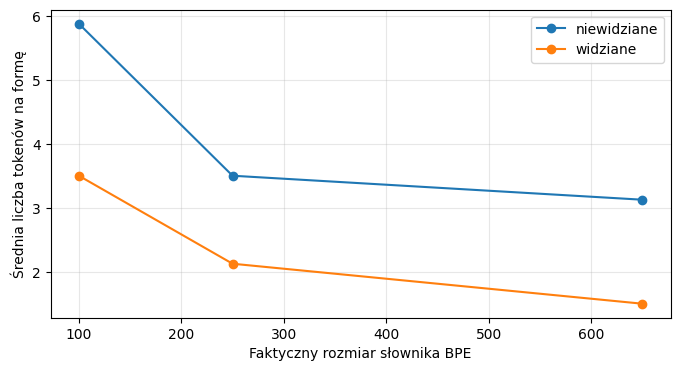

In [6]:
tabela_podzialow = pd.DataFrame(podzialy)
display(tabela_podzialow[tabela_podzialow["forma"].isin(["zamkami", "kluczami"])].sort_values(["forma","limit"]))
for forma in ["zamkami", "kluczami"]:
    print("Forma niewidziana:", forma)
    for limit in LIMITY:
        print(limit, TOKENIZERY[limit].get_vocab_size(), TOKENIZERY[limit].encode(forma).tokens)
print("Przykładowe formy treningowe zawierające podobne fragmenty:")
for fragment in ["zam", "klucz", "ami", "am", "mi"]:
    print(fragment, sorted([w for w in SLOWNICTWO if fragment in w])[:15])
fig, ax=plt.subplots(figsize=(8,4))
for grupa,g in tabela_bpe.groupby("grupa"):
    ax.plot(g["rozmiar_faktyczny"],g["tokeny_na_slowo"],marker="o",label=grupa)
ax.set(xlabel="Faktyczny rozmiar słownika BPE",ylabel="Średnia liczba tokenów na formę")
ax.legend()
ax.grid(alpha=.3)
plt.show()

In [7]:
WYBRANE_BUDOWLA = KORPUS_BUDOWLA[:12]
WYBRANE_MECHANIZM = KORPUS_MECHANIZM[:12]
WARIANT_A = KORPUS_TLO + WYBRANE_BUDOWLA + [KORPUS_MECHANIZM[i] for i in [0,2,12,16]]
WARIANT_B = KORPUS_TLO + KORPUS_BUDOWLA[:4] + WYBRANE_MECHANIZM
assert len(WARIANT_A) == len(WARIANT_B) == 36
assert sum(z.count("zamek") for z in map(przygotuj,WARIANT_A)) == 16
assert sum(z.count("zamek") for z in map(przygotuj,WARIANT_B)) == 16
print("Wariant A: 20 zdań tła, 12 o budowli, 4 o mechanizmie")
print("Wariant B: 20 zdań tła, 4 o budowli, 12 o mechanizmie")
print("W obu wariantach po 36 zdań i po 16 wystąpień słowa zamek")
PARAMETRY = {"vector_size":50,"window":4,"min_count":1,"sg":1,"epochs":400,"seed":SEED,"workers":1,"negative":5}
MODELE = {}
for nazwa, wariant in [("A",WARIANT_A),("B",WARIANT_B)]:
    zdania = [przygotuj(s) for s in wariant]
    m = Word2Vec(sentences=zdania,**PARAMETRY)
    MODELE[nazwa] = m
    print(nazwa,"liczba zdań:",len(zdania),"słownictwo:",len(m.wv),"zamek:",m.wv.get_vecattr("zamek","count"))
print("Ustawienia:",PARAMETRY)

Wariant A: 20 zdań tła, 12 o budowli, 4 o mechanizmie
Wariant B: 20 zdań tła, 4 o budowli, 12 o mechanizmie
W obu wariantach po 36 zdań i po 16 wystąpień słowa zamek
A liczba zdań: 36 słownictwo: 184 zamek: 16
B liczba zdań: 36 słownictwo: 183 zamek: 16
Ustawienia: {'vector_size': 50, 'window': 4, 'min_count': 1, 'sg': 1, 'epochs': 400, 'seed': 42, 'workers': 1, 'negative': 5}


In [8]:
rankingi=[]
for wariant, model in MODELE.items():
    print("Wariant",wariant)
    for miejsce,(slowo,cos) in enumerate(model.wv.most_similar("zamek",topn=5),start=1):
        rankingi.append({"wariant":wariant,"miejsce":miejsce,"sąsiad":slowo,"cosinus":round(float(cos),4)})
display(pd.DataFrame(rankingi))
for slowo in ["rycerz","wieżę","zamek","klucz","ślusarz","drzwi"]:
    print(slowo, "A:", slowo in MODELE["A"].wv, "B:", slowo in MODELE["B"].wv)
print("Przykładowe zdania z dwóch znaczeń:")
for s in [KORPUS_BUDOWLA[1],KORPUS_BUDOWLA[8],KORPUS_MECHANIZM[0],KORPUS_MECHANIZM[5]]:
    print(s)

Wariant A
Wariant B


,wariant,miejsce,sąsiad,cosinus
0,A,1,dawne,0.6110
1,A,2,murem,0.6107
2,A,3,wymienił,0.6094
3,A,4,bada,0.6091
4,A,5,otoczony,0.6084
5,B,1,wejściowych,0.7031
6,B,2,sklepie,0.7026
7,B,3,kupiłem,0.6971
8,B,4,klucz,0.6610
9,B,5,otwiera,0.6462


rycerz A: True B: True
wieżę A: True B: True
zamek A: True B: True
klucz A: True B: True
ślusarz A: True B: True
drzwi A: False B: True
Przykładowe zdania z dwóch znaczeń:
Turysta ogląda zamek i fotografuje kamienną wieżę.
Z wieży widać zamek oraz pobliskie pola.
Ślusarz wymienił zamek w drzwiach mieszkania.
W sklepie kupiłem zamek do drzwi wejściowych.


Słowa wybrane przed oceną:
Budowla: ['rycerz', 'wieżę', 'kamienny', 'dziedziniec', 'bramę']
Mechanizm: ['klucz', 'drzwiach', 'ślusarz', 'mechanizm', 'metalowy', 'furtki']


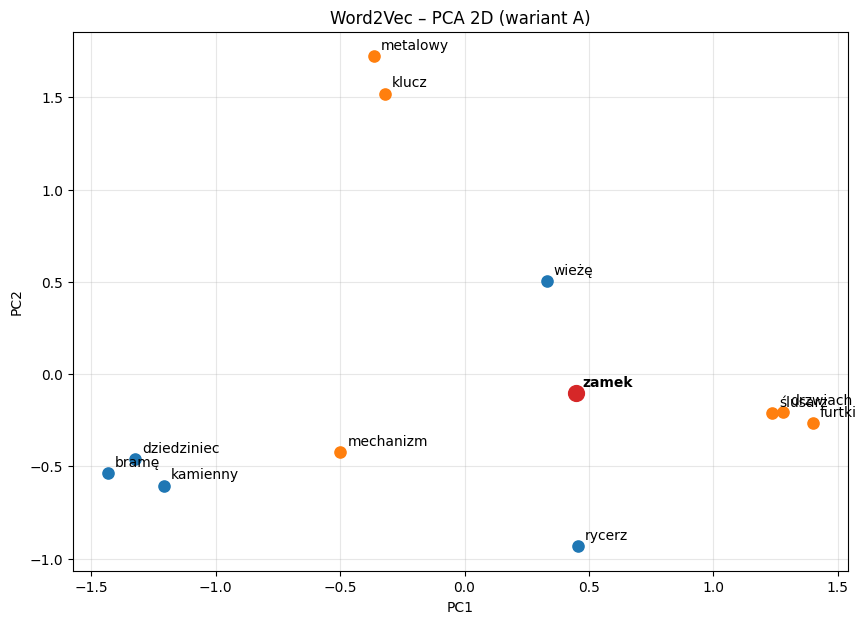

In [9]:
GRUPA_BUDOWLA = ["rycerz", "zamek", "wieżę", "kamienny", "dziedziniec", "bramę"]
GRUPA_MECHANIZM = ["klucz", "drzwiach", "ślusarz", "mechanizm", "metalowy", "furtki"]
GRUPA_BUDOWLA = [w for w in GRUPA_BUDOWLA if w != "zamek"]
model = MODELE["A"]
print("Słowa wybrane przed oceną:")
print("Budowla:",GRUPA_BUDOWLA)
print("Mechanizm:",GRUPA_MECHANIZM)
assert all(w in model.wv for w in GRUPA_BUDOWLA+GRUPA_MECHANIZM+["zamek"])
slowa = GRUPA_BUDOWLA + GRUPA_MECHANIZM + ["zamek"]
wektory = np.stack([model.wv[w] for w in slowa])
XY = PCA(n_components=2,random_state=SEED).fit_transform(wektory)
fig, ax=plt.subplots(figsize=(10,7))
for i,w in enumerate(slowa):
    kolor = "tab:blue" if w in GRUPA_BUDOWLA else "tab:orange" if w in GRUPA_MECHANIZM else "tab:red"
    ax.scatter(XY[i,0],XY[i,1],color=kolor,s=130 if w=="zamek" else 65,zorder=3)
    ax.annotate(w,(XY[i,0],XY[i,1]),xytext=(5,5),textcoords="offset points",fontsize=10,weight="bold" if w=="zamek" else "normal")
ax.set(xlabel="PC1",ylabel="PC2",title="Word2Vec – PCA 2D (wariant A)")
ax.grid(alpha=.3)
plt.show()

In [10]:
from itertools import combinations

def cos(a,b):
    x = model.wv[a]
    y = model.wv[b]
    return float(x @ y / (np.linalg.norm(x)*np.linalg.norm(y)))

PARY_WEWN_BUD = list(combinations(GRUPA_BUDOWLA,2))
PARY_WEWN_MECH = list(combinations(GRUPA_MECHANIZM,2))
PARY_MIEDZY = [(a,b) for a in GRUPA_BUDOWLA for b in GRUPA_MECHANIZM]
porownanie = pd.DataFrame([{"grupa":"wewnątrz budowli","liczba_par":len(PARY_WEWN_BUD),"sredni_cos":np.mean([cos(a,b) for a,b in PARY_WEWN_BUD])},
{"grupa":"wewnątrz mechanizmu","liczba_par":len(PARY_WEWN_MECH),"sredni_cos":np.mean([cos(a,b) for a,b in PARY_WEWN_MECH])},
{"grupa":"między grupami","liczba_par":len(PARY_MIEDZY),"sredni_cos":np.mean([cos(a,b) for a,b in PARY_MIEDZY])}])
display(porownanie)
for a,b in [("rycerz","wieżę"),("klucz","drzwiach"),("rycerz","ślusarz")]:
    print(a,b,round(cos(a,b),4))
print("Łączny zrzut wyników do sprawozdania:")
display(tabela_bpe, pd.DataFrame(rankingi),porownanie)

,grupa,liczba_par,sredni_cos
0,wewnątrz budowli,10,0.627521
1,wewnątrz mechanizmu,15,0.499603
2,między grupami,30,0.461217


rycerz wieżę 0.4127
klucz drzwiach 0.4163
rycerz ślusarz 0.4564
Łączny zrzut wyników do sprawozdania:


,limit,rozmiar_faktyczny,grupa,tokeny_na_slowo,formy_z_UNK
0,100,100,widziane,3.500,0
1,100,100,niewidziane,5.875,0
2,250,250,widziane,2.125,0
3,250,250,niewidziane,3.500,0
4,650,650,widziane,1.500,0
5,650,650,niewidziane,3.125,0


,wariant,miejsce,sąsiad,cosinus
0,A,1,dawne,0.6110
1,A,2,murem,0.6107
2,A,3,wymienił,0.6094
3,A,4,bada,0.6091
4,A,5,otoczony,0.6084
5,B,1,wejściowych,0.7031
6,B,2,sklepie,0.7026
7,B,3,kupiłem,0.6971
8,B,4,klucz,0.6610
9,B,5,otwiera,0.6462


,grupa,liczba_par,sredni_cos
0,wewnątrz budowli,10,0.627521
1,wewnątrz mechanizmu,15,0.499603
2,między grupami,30,0.461217
